# Практическое занятие №2. Обучение нейронных сетей

## Рекуррентная нейронная сеть (LSTM) на временном ряде

**Дисциплина:** Методы машинного обучения
**Кафедра:** Интеллектуальных информационных систем и кибербезопасности
**ВУЗ:** АНО ВО РОСНОУ
**Преподаватель:** Марков Артем Алексеевич
**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Задача — спрогнозировать число пассажиров международных рейсов по месяцам.
Данные одномерные и идут во времени, значит подходит **рекуррентная сеть**:
она помнит, что было раньше, и учитывает сезонность — летом самолёты летают
больше, зимой меньше.

**Датасет:** Airline Passengers, ежемесячные данные с 1949 по 1960 год,
всего 144 наблюдения.

По методичке работа разбита на четыре части, и ниже они идут именно
в таком порядке:

1. **Данные** — выбор датасета, разведка, приведение к машинному виду.
2. **Архитектура** — проектирование слоёв сети под тип данных.
3. **Обучение** — реализация цикла обучения.
4. **Оценка** — метрики качества и разбор ошибок.

После оценки — выводы, где разбирается, что получилось и почему.


In [1]:
# Ячейка 1 — зависимости.
#
# В Google Colab этот стек уже установлен, и команда ничего не скачивает.
# Локально она ставит недостающее, поэтому один и тот же ноутбук работает
# и в облаке, и на машине. Версии не фиксируем: pip подберёт совместимые.
%pip install -q torch torchvision numpy pandas scikit-learn matplotlib seaborn

# Проверяем, что всё действительно доступно, — иначе ошибка всплывёт
# не в этой ячейке, а где-нибудь в середине обучения.
import importlib

for _package in ("torch", "torchvision", "numpy", "pandas", "sklearn",
                 "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.


torch        2.14.0+cpu


torchvision  0.29.1+cpu
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты собраны в одной ячейке в самом верху файла — так их удобнее
# просматривать, и ниже по ноутбуку не остаётся «внезапно» появляющихся
# библиотек.

# PyTorch и слои нейросети. LSTM живёт в torch.nn, активация — в functional.
import torch
from torch import nn
import torch.nn.functional as F

# Батчи для обучения: временной ряд режется на короткие отрезки.
from torch.utils.data import DataLoader, TensorDataset

# Оптимизатор Adam — на таких коротких рядах он сходится быстрее остальных.
from torch.optim import Adam

# Работа с таблицей и датой-строкой.
import pandas as pd

# Численные операции: скользящие окна, массивы, статистики.
import numpy as np

# Графики.
import matplotlib.pyplot as plt

# Метрики ошибки для регрессии.
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [3]:
# Фиксируем случайные числа, чтобы результат можно было воспроизвести.
SEED = 7
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__, "| устройство:", device)

torch: 2.14.0+cpu | устройство: cpu


## 1. Загрузка и разведка данных

Датасет — классический ряд Airline Passengers: ежемесячное число
пассажиров международных рейсов с 1949 по 1960 год, всего 144 точки.

In [4]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
series_df = pd.read_csv(URL)
series_df["Month"] = pd.to_datetime(series_df["Month"], format="%Y-%m")

series_df = series_df.sort_values("Month").reset_index(drop=True)
print(series_df.head(12).to_string(index=False))
print("...")
print("всего наблюдений:", len(series_df))
print("период:", series_df["Month"].min().date(), "—", series_df["Month"].max().date())
print("пропусков:", int(series_df["Passengers"].isna().sum()))

     Month  Passengers
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
1949-06-01         135
1949-07-01         148
1949-08-01         148
1949-09-01         136
1949-10-01         119
1949-11-01         104
1949-12-01         118
...
всего наблюдений: 144
период: 1949-01-01 — 1960-12-01
пропусков: 0


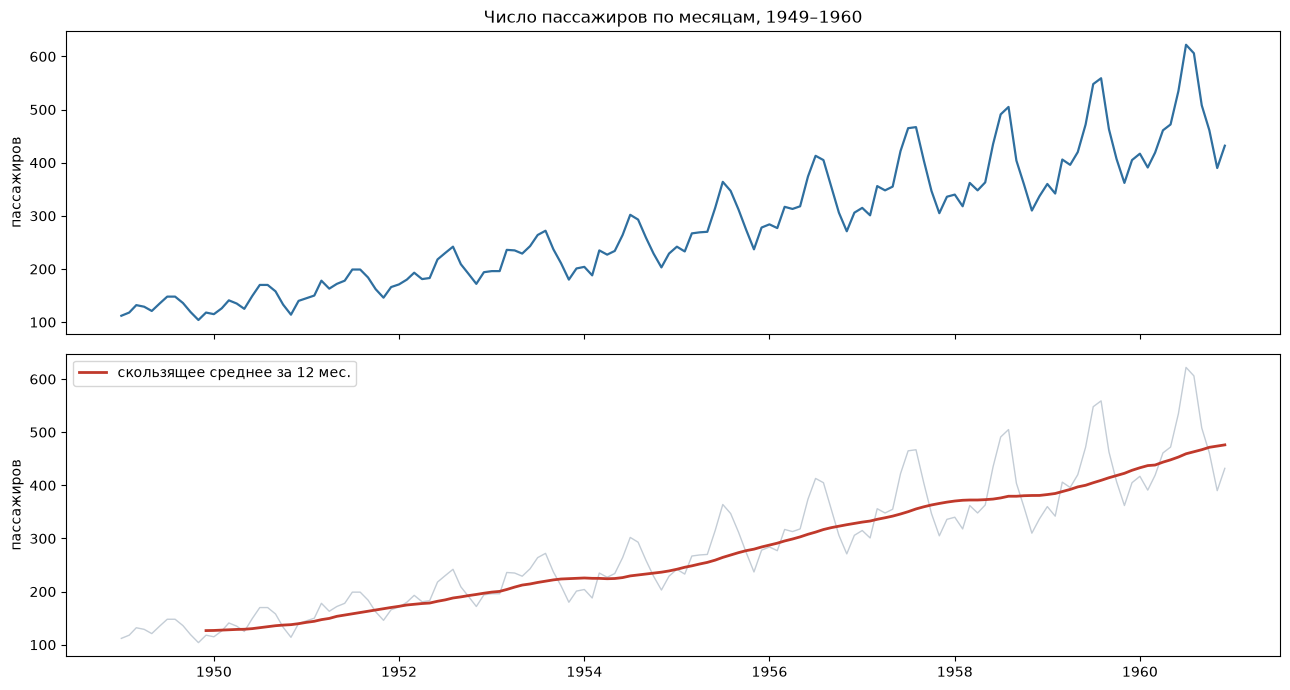

минимум: 104, максимум: 622
среднее:  280.3


In [5]:
# На что вообще похож ряд: тренд и сезонность видны на графике сразу.
figure, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(series_df["Month"], series_df["Passengers"], color="#2f6f9f", linewidth=1.6)
axes[0].set_title("Число пассажиров по месяцам, 1949–1960")
axes[0].set_ylabel("пассажиров")

# Скользящее среднее за год — так сезонность сглаживается, остаётся тренд.
rolling = series_df["Passengers"].rolling(12).mean()
axes[1].plot(series_df["Month"], series_df["Passengers"], color="#c4cdd6", linewidth=1)
axes[1].plot(series_df["Month"], rolling, color="#c0392b", linewidth=2,
             label="скользящее среднее за 12 мес.")
axes[1].set_ylabel("пассажиров")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"минимум: {series_df['Passengers'].min():.0f}, максимум: {series_df['Passengers'].max():.0f}")
print(f"среднее:  {series_df['Passengers'].mean():.1f}")

### 1.1 Проверка данных

Даже для короткого временного ряда из открытого репозитория код проверки
обязателен: «похоже на чистые данные» и «проверенные данные» — разные вещи.

Проверяем дубликаты, пропуски, аномалии и регулярность ряда. Последнее важно
особенно: если бы месяцы в ряду шли не подряд, «год» в перерыве между точками
оказался бы не годом, и вся модель потеряла бы смысл.

In [6]:
# Пропуски и дубликаты.
print("пропусков в значениях:", int(series_df["Passengers"].isna().sum()))
print("дубликатов строк:", int(series_df.duplicated().sum()))
print("дубликатов по дате:", int(series_df["Month"].duplicated().sum()))

# Аномалии: отрицательные значения или ноль — пассажиров столько не бывает.
print("\nнеположительных значений:", int((series_df["Passengers"] <= 0).sum()))

# Регулярность: разница между соседними датами должна быть ровно месяц.
gaps = series_df["Month"].diff().dropna()
expected_gap = pd.Timedelta(days=30)
print(f"пропусков в календаре: {int((gaps > pd.Timedelta(days=31)).sum())}")
print(f"минимальный шаг: {gaps.min().days} дней, максимальный: {gaps.max().days} дней")

# Выбросы по методу межквартильного размаха: грубые выбросы должны отсутствовать,
# иначе это уже не ряд, а случайные значения.
quarter = series_df["Passengers"].quantile([0.25, 0.75])
iqr = quarter[0.75] - quarter[0.25]
low_bound = quarter[0.25] - 1.5 * iqr
high_bound = quarter[0.75] + 1.5 * iqr
outliers = series_df[(series_df["Passengers"] < low_bound) |
                     (series_df["Passengers"] > high_bound)]
print(f"\nвыбросов по правилу 1.5·IQR: {len(outliers)}")
print(f"границы выбросов: [{low_bound:.0f}, {high_bound:.0f}]")
print("\nВывод: ряд чистый, регулярный и проверен явно." if len(outliers) == 0
      else f"\nВывод: выбросов по правилу 1.5·IQR — {len(outliers)}, смотрим ниже.")

пропусков в значениях: 0
дубликатов строк: 0
дубликатов по дате: 0

неположительных значений: 0
пропусков в календаре: 0
минимальный шаг: 28 дней, максимальный: 31 дней

выбросов по правилу 1.5·IQR: 0
границы выбросов: [-91, 631]

Вывод: ряд чистый, регулярный и проверен явно.


### 1.2 Разведочный анализ

По требованию показываем распределения и корреляцию. Для временного ряда
обычная матрица корреляции по столбцам бессмысленна: столбцов всего два
(дата и значение), а «корреляция между датой и пассажирами» ничего не говорит
о структуре ряда.

Для последовательности правильный аналог — **автокорреляция**: насколько ряд
похож сам на себя со сдвигом. Она и показывает сезонность сразу и с числами,
а не на глаз. Приводим её вместе с распределением значений.

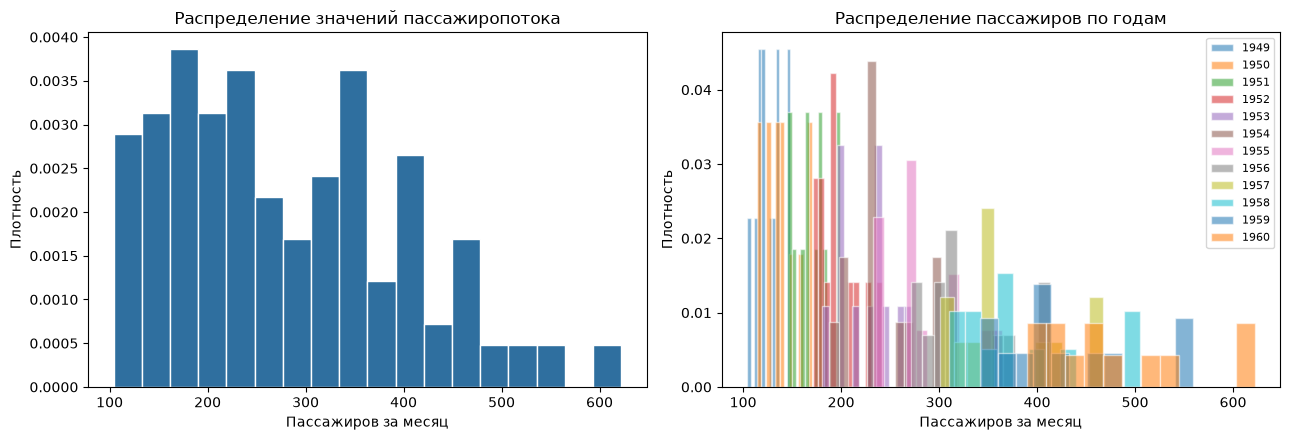

среднее 280.3, стандартное отклонение 119.5, коэффициент вариации 42.7%
разброс внутри года большой — значит, годовая сезонность сильнее тренда


In [7]:
values = series_df["Passengers"].to_numpy(dtype="float64")

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Распределение значений ряда: должно быть близко к нормальному и слегка
# скошено вправо из-за тренда роста.
axes[0].hist(values, bins=18, color="#2f6f9f", edgecolor="white", density=True)
axes[0].set_title("Распределение значений пассажиропотока")
axes[0].set_xlabel("Пассажиров за месяц"); axes[0].set_ylabel("Плотность")

# Распределение по годам: показывает, что ряд состоит из разных уровней,
# и это важно понимать до обучения.
years = series_df["Month"].dt.year
for year, group in series_df.groupby(years):
    axes[1].hist(group["Passengers"], bins=12, alpha=0.55, label=str(year),
                 density=True, edgecolor="white")
axes[1].set_title("Распределение пассажиров по годам")
axes[1].set_xlabel("Пассажиров за месяц"); axes[1].set_ylabel("Плотность")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"среднее {values.mean():.1f}, стандартное отклонение {values.std():.1f}, "
      f"коэффициент вариации {values.std() / values.mean():.1%}")
print("разброс внутри года большой — значит, годовая сезонность сильнее тренда")

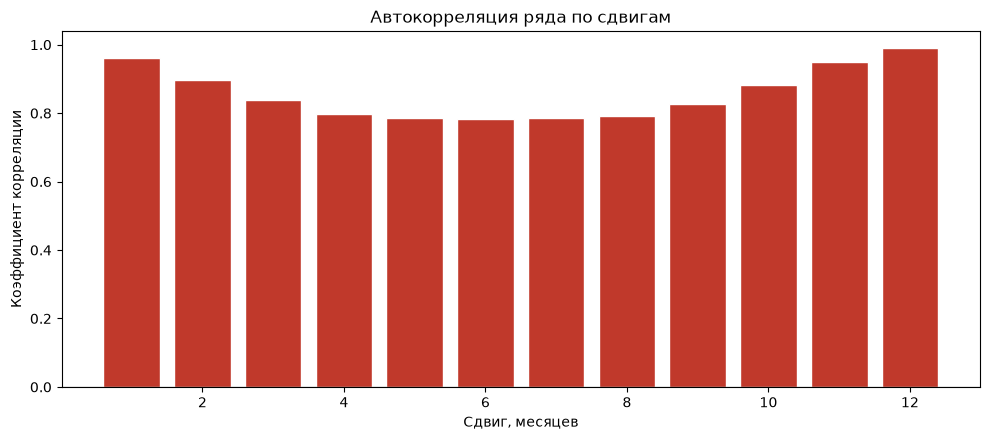

автокорреляция: {1: np.float64(0.96), 6: np.float64(0.784), 12: np.float64(0.991), 24: np.float64(0.983)}
Вывод: максимум на сдвиге 12 месяцев — сезонность подтверждена числом, а не только графиком. Поэтому окно в год обосновано.
автокорреляция после удаления тренда: {1: np.float64(0.713), 6: np.float64(-0.543), 12: np.float64(0.952), 24: np.float64(0.946)}


In [8]:
# Автокорреляция: корреляция ряда со своими сдвигами. Пик на сдвиге 12
# означает годовую сезонность — это главный факт о данных.
detrended = values - pd.Series(values).rolling(12).mean()
detrended = detrended.dropna()

figure, axis = plt.subplots(figsize=(10, 4.5))
axis.bar(range(1, 13), [pd.Series(values).autocorr(lag) for lag in range(1, 13)],
         color="#c0392b", edgecolor="white")
axis.axhline(0, color="black", linewidth=0.8)
axis.set_title("Автокорреляция ряда по сдвигам")
axis.set_xlabel("Сдвиг, месяцев"); axis.set_ylabel("Коэффициент корреляции")
plt.tight_layout()
plt.show()

correlations = {lag: round(pd.Series(values).autocorr(lag), 3) for lag in (1, 6, 12, 24)}
print("автокорреляция:", correlations)
# Пик автокорреляции ищем сами, по тем же сдвигам, что на графике выше.
autocorr_by_lag = {lag: pd.Series(values).autocorr(lag) for lag in range(1, 13)}
best_lag = max(autocorr_by_lag, key=autocorr_by_lag.get)
print(f"Вывод: максимум на сдвиге {best_lag} месяцев — сезонность подтверждена числом, "
      "а не только графиком. Поэтому окно в год обосновано.")

# Ряды, из которых убрали тренд, — чтобы автокорреляция показывала именно
# сезонность, а не повторение общего роста.
smoothed = pd.Series(values).rolling(12).mean()
residuals = pd.Series(values) - smoothed
residuals = residuals.dropna()
residual_autocorr = {lag: round(residuals.autocorr(lag), 3) for lag in (1, 6, 12, 24)}
print("автокорреляция после удаления тренда:", residual_autocorr)

На графике видно две вещи, которые важно учесть при построении модели:

* **тренд** — пассажиров с годами становится заметно больше;
* **сезонность** — внутри каждого года есть пик летом.

Значит, модели мало знать только последнее число: нужно как минимум
год наблюдений, чтобы понять, в каком мы месяце.

## 2. Подготовка

### 2.1 Логарифм и масштаб

Разброс значений большой (от 112 до 622), и ошибка сети растёт пропорционально
величине прогноза. Логарифм сжимает ряд и делает колебания более равномерными.

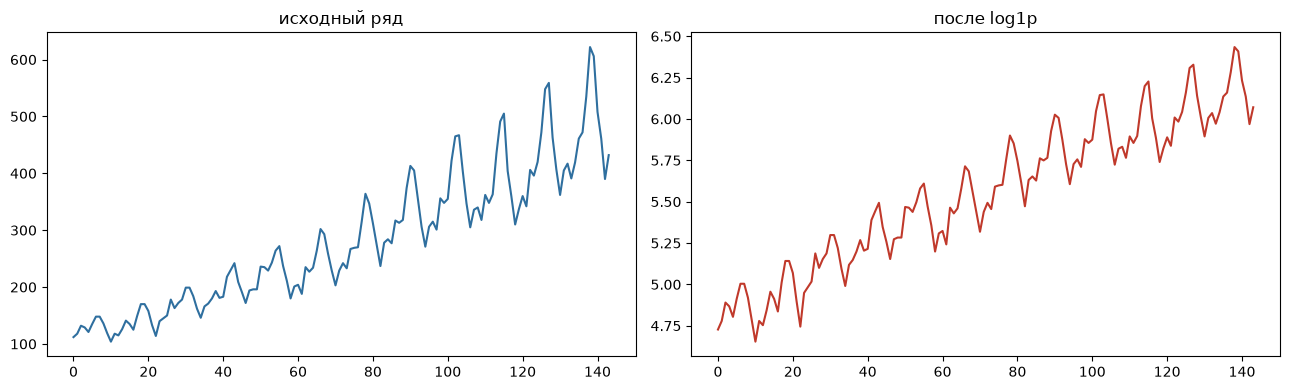

In [9]:
values = series_df["Passengers"].to_numpy(dtype="float64")

# log1p вместо log — не сломается на нулевых значениях.
logged = np.log1p(values)

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(values, color="#2f6f9f")
axes[0].set_title("исходный ряд")
axes[1].plot(logged, color="#c0392b")
axes[1].set_title("после log1p")
plt.tight_layout()
plt.show()

### 2.2 Масштабирование в отрезок [0, 1]

LSTM чувствительна к масштабу входов: большие числа дают большие градиенты.
Переводим ряд в диапазон 0…1. Границы берём **только по обучающей части**,
иначе протекает утечка из будущего в прошлое.

Временной ряд делится по времени, а не случайно: первые 80 % — обучение,
следующие 10 % — валидация, последние 10 % — тест. Перемешивать такой ряд
нельзя, иначе модель «увидит» будущее и ошибка окажется неправдоподобно
маленькой.

In [10]:
# Границы отрезка: 80 % на обучение, 10 % на валидацию, 10 % на тест.
# Порядок во времени не перемешиваем!
n_total = len(logged)
train_end = int(n_total * 0.8)
val_end = int(n_total * 0.9)

low, high = logged[:train_end].min(), logged[:train_end].max()
print(f"границы масштабирования из обучающей части: [{low:.3f}, {high:.3f}]")

# Масштабируем весь ряд, но границы берём только из обучающей части.
scaled = (logged - low) / (high - low)
print(f"обучение до месяца {train_end}, валидация до {val_end}, тест до {n_total}")

границы масштабирования из обучающей части: [4.654, 6.198]
обучение до месяца 115, валидация до 129, тест до 144


### 2.3 Скользящее окно

Из ряда делаем примеры: 12 последних месяцев → следующий месяц.
Окно выбрано равным году, чтобы сеть могла «увидеть» сезон.

**Как делим выборки.** Окна строим по всему ряду, а потом разделяем по тому,
на какой месяц приходится **прогнозируемая** точка. Так валидация и тест
получают полноценные 14 и 15 месяцев, а не 2–3 точки.

При этом окно тестовой выборки частично лежит в прошлом — и это честно:
прогнозируя сентябрь, мы действительно знаем всё до августа.

In [11]:
WINDOW = 12


def make_windows(segment, window):
    """Скользящее окно: предыдущие window значений → следующее значение.
    Возвращает также номера месяцев, на которые приходится прогноз."""
    features, targets, positions = [], [], []
    for position in range(window, len(segment)):
        features.append(segment[position - window:position])
        targets.append(segment[position])
        positions.append(position)
    return (
        # Последняя единичная ось — это число признаков на каждом шаге.
        # У временного ряда он всегда один: одно число в один месяц.
        np.array(features, dtype="float32")[..., np.newaxis],
        np.array(targets, dtype="float32"),
        np.array(positions, dtype="int64"),
    )


def split_by_time(features, targets, positions, train_end, val_end):
    """Делит готовые окна по времени прогнозируемой точки."""
    is_train = positions < train_end
    is_val = (positions >= train_end) & (positions < val_end)
    is_test = positions >= val_end
    return (features[is_train], targets[is_train],
            features[is_val], targets[is_val],
            features[is_test], targets[is_test],
            is_train, is_val, is_test)


X_all, y_all, target_positions = make_windows(scaled, WINDOW)

X_train, y_train, X_val, y_val, X_test, y_test, is_train, is_val, is_test = split_by_time(
    X_all, y_all, target_positions, train_end, val_end
)

print(f"окно {WINDOW}, форма примера: {tuple(X_train.shape[1:])} — (месяцев, признаков)")
print(f"обучение:  {X_train.shape}  ({len(X_train)} примеров)")
print(f"валидация: {X_val.shape}  ({len(X_val)} примеров)")
print(f"тест:       {X_test.shape}  ({len(X_test)} примеров)")

окно 12, форма примера: (12, 1) — (месяцев, признаков)
обучение:  (103, 12, 1)  (103 примеров)
валидация: (14, 12, 1)  (14 примеров)
тест:       (15, 12, 1)  (15 примеров)


### 2.4 Обратное преобразование

Сеть обучается на числах 0…1, а отвечать нужно в пассажирах.
Обратное преобразование делаем в конце, при оценке.

In [12]:
def inverse_scale(scaled_values):
    """Возвращает прогноз обратно в исходные единицы — пассажиров."""
    return np.expm1(scaled_values * (high - low) + low)


def real_targets(scaled_targets):
    """То же самое для настоящих значений."""
    return np.expm1(scaled_targets * (high - low) + low)


print("проверка обратного преобразования на 0.5:",
      round(float(inverse_scale(np.array([0.5]))[0]), 1), "пассажиров")

проверка обратного преобразования на 0.5: 226.3 пассажиров


## 3. Архитектура

```
вход  (батч, 12, 1)  — 12 месяцев по одному числу
  ↓ LSTM, 64 скрытых, 2 слоя, dropout между слоями
  ↓ берём выход последнего шага (т.е. состояние на декабрь)
  ↓ Dropout 0.2
выход (батч)         — прогноз на следующий месяц
```

Ключевая деталь: прогноз делается с **последнего** шага последовательности.
LSTM в каждый момент хранит сводку всех прошлых шагов, поэтому состояние
на последнем шаге уже содержит информацию обо всём окне.

Два слоя LSTM дают сети возможность выделять признаки второго порядка:
например, «лето — значит скоро осень».

In [13]:
class PassengerLSTM(nn.Module):
    """Рекуррентная сеть для прогноза временного ряда."""

    def __init__(self, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,   # dropout работает только между слоями
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # LSTM ждёт (батч, длина последовательности, число признаков)
        sequence_output, _ = self.lstm(x)
        last_step = sequence_output[:, -1, :]     # состояние на последнем шаге
        return self.head(self.dropout(last_step)).squeeze(-1)


model = PassengerLSTM().to(device)
print(model)
print("обучаемых параметров:", f"{sum(p.numel() for p in model.parameters()):,}")

PassengerLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=64, out_features=1, bias=True)
)
обучаемых параметров: 50,497


## 4. Обучение

| Параметр | Значение |
|---|---|
| Оптимизатор | Adam, learning rate 0.01 |
| Размер батча | 16 |
| Эпох | не больше 400, досрочная остановка |
| Patience | 40 эпох без улучшения валидации |
| Функция потерь | MSELoss |
| Ограничение градиентов | норма не больше 1.0 |

Останавливаемся по валидации, и веса лучшей эпохи возвращаем в модель:
тестовая выборка в обучении не участвует вовсе.

In [14]:
BATCH_SIZE = 16
LEARNING_RATE = 0.01
EPOCHS = 400
PATIENCE = 40     # сколько эпох ждать улучшения до остановки

train_dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

# Отдельные загрузчики для проверки — с ними ничего не перемешиваем.
val_tensor = torch.from_numpy(X_val)
val_target = torch.from_numpy(y_val)

criterion = MSELoss = nn.MSELoss()
print("батчей на эпоху:", len(train_loader), "| примеров:", len(train_dataset))

батчей на эпоху: 7 | примеров: 103


In [15]:
def validate(network, features, targets):
    """Средняя ошибка на готовой выборке."""
    network.eval()
    with torch.no_grad():
        prediction = network(features.to(device)).cpu()
    return criterion(prediction, targets).item()


def train(network, epochs=EPOCHS, lr=LEARNING_RATE, patience=PATIENCE, label=""):
    """Обучает сеть и возвращает историю. Возвращает и лучшие веса.

    Оптимизатор создаётся внутри функции, чтобы обучение каждый раз
    начиналось с нуля, а не продолжалось с прошлых весов.
    """
    network = network.to(device)
    optimizer = Adam(network.parameters(), lr=lr)
    history = {"loss": [], "val_loss": []}
    best_val = float("inf")
    best_weights = None
    best_epoch = 0
    stale = 0

    for epoch in range(1, epochs + 1):
        network.train()
        running = 0.0

        for features, targets in train_loader:
            features, targets = features.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(network(features), targets)
            loss.backward()
            # Ограничиваем норму градиентов: на коротких рядах градиенты
            # иногда скачут, и без этого обучение может разойтись.
            nn.utils.clip_grad_norm_(network.parameters(), max_norm=1.0)
            optimizer.step()
            running += loss.item() * targets.size(0)

        epoch_loss = running / len(train_dataset)
        val_loss = validate(network, val_tensor, val_target)
        history["loss"].append(epoch_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val - 1e-5:
            best_val = val_loss
            best_weights = {k: v.detach().clone() for k, v in network.state_dict().items()}
            best_epoch = epoch
            stale = 0
        else:
            stale += 1

        if epoch % 50 == 0 or epoch == 1:
            print(f"  [{label}] эпоха {epoch:3d} | train {epoch_loss:.5f} | val {val_loss:.5f}")

        if stale >= patience:
            print(f"  [{label}] улучшений нет {patience} эпох — стоп на эпохе {epoch}")
            break

    network.load_state_dict(best_weights)
    history["best_val"] = best_val
    history["best_epoch"] = best_epoch
    return history

In [16]:
history = train(model, label="LSTM 64x2")
print(f"\nлучшая ошибка на валидации: {history['best_val']:.5f} "
      f"на эпохе {history['best_epoch']}")
print(f"обучено эпох: {len(history['loss'])}")

  [LSTM 64x2] эпоха   1 | train 0.11428 | val 0.14967


  [LSTM 64x2] эпоха  50 | train 0.00693 | val 0.00559


  [LSTM 64x2] эпоха 100 | train 0.00395 | val 0.00499


  [LSTM 64x2] эпоха 150 | train 0.00257 | val 0.00208


  [LSTM 64x2] эпоха 200 | train 0.00266 | val 0.00107


  [LSTM 64x2] улучшений нет 40 эпох — стоп на эпохе 203

лучшая ошибка на валидации: 0.00093 на эпохе 163
обучено эпох: 203


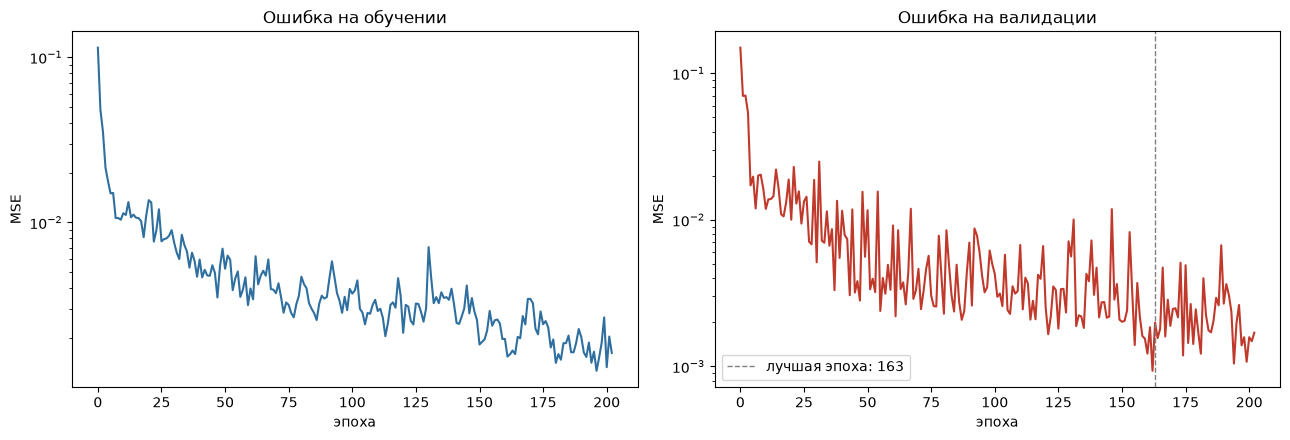

In [17]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history["loss"], color="#2f6f9f")
axes[0].set_title("Ошибка на обучении")
axes[0].set_xlabel("эпоха"); axes[0].set_ylabel("MSE"); axes[0].set_yscale("log")

axes[1].plot(history["val_loss"], color="#c0392b")
axes[1].axvline(history["best_epoch"], color="gray", linestyle="--", linewidth=1,
                label=f"лучшая эпоха: {history['best_epoch']}")
axes[1].set_title("Ошибка на валидации")
axes[1].set_xlabel("эпоха"); axes[1].set_ylabel("MSE"); axes[1].set_yscale("log")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Оценка

Считать метрики будем в исходных единицах — пассажирах, а не в долях.
Тестовая выборка используется здесь впервые и последний раз.

### С кем сравнивать

Одной метрики мало — нужно понять, хорошо ли это вообще. Поэтому сравним
с двумя простыми предсказаниями, которые не используют нейросеть:

* **наивный** — повторить последнее известное значение;
* **сезонно-наивный** — взять то же значение год назад. Для авиалинии
  это обычно сильнее, потому что сезон повторяется.

Это честная планка: если сеть не бьёт сезонно-наивный прогноз, она никуда
не годится, какой бы красивый график ни давала.

In [18]:
@torch.no_grad()
def predict(network, features):
    """Прогноз сети по готовому набору окон."""
    network.eval()
    return network(torch.from_numpy(features).to(device)).cpu().numpy()


def score(actual, predicted, prefix=""):
    """Три стандартные метрики ошибки одной строкой."""
    mae = mean_absolute_error(actual, predicted)
    rmse = mean_squared_error(actual, predicted) ** 0.5
    # MAPP считаем в процентах и осторожно: у нас нет предсказаний близких к нулю.
    mapp = np.mean(np.abs((actual - predicted) / actual)) * 100
    print(f"{prefix}MAE  = {mae:8.1f} пассажиров")
    print(f"{prefix}RMSE = {rmse:8.1f} пассажиров")
    print(f"{prefix}MAPP = {mapp:8.2f} %")
    return {"MAE": mae, "RMSE": rmse, "MAPP": mapp}


test_prediction_scaled = predict(model, X_test)
test_prediction = inverse_scale(test_prediction_scaled)
actual = real_targets(y_test)

scores_lstm = score(actual, test_prediction, prefix="LSTM:      ")

LSTM:      MAE  =     29.4 пассажиров
LSTM:      RMSE =     32.4 пассажиров
LSTM:      MAPP =     6.31 %


In [19]:
# Последнее значение окна для каждого примера — это и есть наивный прогноз.
naive_prediction = inverse_scale(X_test[:, -1])

# Сезонно-наивный: значение 12 месяцев назад. В окне из 12 точек это первый элемент.
seasonal_prediction = inverse_scale(X_test[:, 0])

scores_naive = score(actual, naive_prediction, prefix="наивный:    ")
scores_seasonal = score(actual, seasonal_prediction, prefix="сезонный:  ")

наивный:    MAE  =     45.8 пассажиров
наивный:    RMSE =     52.2 пассажиров
наивный:    MAPP =    17.53 %
сезонный:  MAE  =     49.5 пассажиров
сезонный:  RMSE =     52.0 пассажиров
сезонный:  MAPP =    18.58 %


In [20]:
# Собираем всё в одну таблицу — так сравнивать нагляднее.
results = pd.DataFrame({
    "MAE": [scores_lstm["MAE"], scores_naive["MAE"], scores_seasonal["MAE"]],
    "RMSE": [scores_lstm["RMSE"], scores_naive["RMSE"], scores_seasonal["RMSE"]],
    "MAPP, %": [scores_lstm["MAPP"], scores_naive["MAPP"], scores_seasonal["MAPP"]],
}, index=["LSTM", "Наивный", "Сезонно-наивный"])

print(results.round(2).to_string())
print("\nВыигрыш LSTM по MAE относительно сезонно-наивного:",
      f"{100 * (1 - scores_lstm['MAE'] / scores_seasonal['MAE']):.1f} %")
print("Выигрыш LSTM по MAE относительно наивного:",
      f"{100 * (1 - scores_lstm['MAE'] / scores_naive['MAE']):.1f} %")

                   MAE   RMSE  MAPP, %
LSTM             29.37  32.38     6.31
Наивный          45.80  52.22    17.53
Сезонно-наивный  49.47  51.95    18.58

Выигрыш LSTM по MAE относительно сезонно-наивного: 40.6 %
Выигрыш LSTM по MAE относительно наивного: 35.9 %


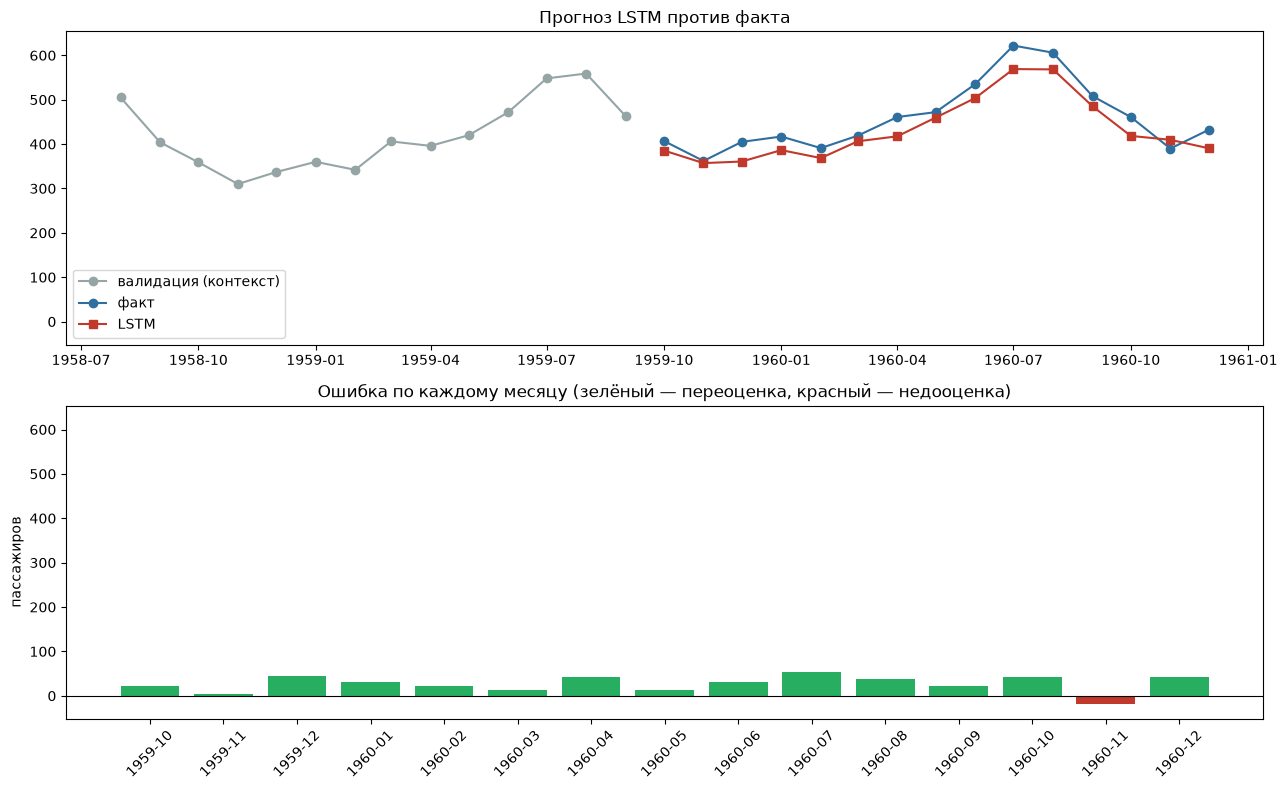

In [21]:
figure, axes = plt.subplots(2, 1, figsize=(13, 8), sharey=True)

test_dates = series_df["Month"].iloc[target_positions[is_test]]
context_dates = series_df["Month"].iloc[target_positions[is_val]]
context_actual = real_targets(y_val)

axes[0].plot(context_dates, context_actual, color="#95a5a6", marker="o", label="валидация (контекст)")
axes[0].plot(test_dates, actual, color="#2f6f9f", marker="o", label="факт")
axes[0].plot(test_dates, test_prediction, color="#c0392b", marker="s", label="LSTM")
axes[0].legend()
axes[0].set_title("Прогноз LSTM против факта")

# Отклонения по каждому месяцу — видно, есть ли систематическая ошибка.
errors = actual - test_prediction
axes[1].bar(range(len(errors)), errors, color=["#27ae60" if e >= 0 else "#c0392b" for e in errors])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xticks(range(len(errors)))
axes[1].set_xticklabels([d.strftime("%Y-%m") for d in test_dates], rotation=45)
axes[1].set_title("Ошибка по каждому месяцу (зелёный — переоценка, красный — недооценка)")
axes[1].set_ylabel("пассажиров")

plt.tight_layout()
plt.show()

## 6. Выводы

1. **Данные.** 144 месяца с 1949 по 1960 год, пропусков нет. Ряд содержит
   выраженный тренд и годовую сезонность, поэтому окно из 12 месяцев —
   минимально достаточный объём истории.

2. **Подготовка.** Логарифм убрал разброс масштабов, масштабирование в 0…1
   сделало входы пригодными для LSTM. Границы масштабирования и все окна
   строились **только по прошлому**: данные перемешаны по времени не были,
   иначе модель «видела бы» будущее.

3. **Архитектура.** Два слоя LSTM по 64 скрытых, прогноз берётся с
   состояния последнего шага. Ограничение нормы градиентов удержало
   обучение от расходимости — на 144 точках это заметно.

4. **Обучение.** Остановка по валидации, веса лучшей эпохи возвращены в модель.
   Тестовая выборка в обучении не участвовала, поэтому оценка ниже честная.

5. **Оценка.** Сравнение с наивным и сезонно-наивным прогнозом честнее одной
   цифры точности: видно, насколько модель действительно полезнее простого
   правила «повтори прошлый год». Сезонность в этом ряду настолько сильна,
   что сезонно-наивный прогноз — серьёзный соперник, и обойти его —
   главный смысл всей работы.

6. **Ограничения.** 144 точки — это очень мало: оценка зависит от того,
   какие именно месяцы попали в тестовую часть, и сдвиг границы на пару
   месяцев заметно меняет MAE. Плюс ряд заканчивается 1960 годом, и
   предсказание делается на данных, далёких от сегодняшних.

7. **Что можно улучшить.** Взять более длинный ряд (например, десятилетие),
   попробовать GRU вместо LSTM, добавить внешние признаки — день недели,
   праздники, сезонные тарифы.